# Memory experiment — syndrome extraction comparison

Compares two syndrome-extraction circuits for the same directional tile code, at the same number of syndrome rounds and decoded with BP+LSD:
- **edge coloring** — qldpc's default `EdgeColoring` strategy: one ancilla per check, coupled directly to its data qubits with CX/CZ gates scheduled by an edge coloring of the Tanner graph. It assumes arbitrary connectivity, so it is a reference, not a planar circuit.
- **directional** — `DirectionalSyndromeMeasurement`: check qubits walk along the directional word (forward) and its inverse (backward) on the square grid with nearest-neighbour CXSWAP/SWAP gates and routing qubits (arXiv:2606.19482).

## Setup

In [1]:
%%capture
%pip install qldpc matplotlib sinter

In [2]:
import csv
import os
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sinter
from matplotlib.figure import Figure
from scipy.stats import beta as beta_distribution

import directional_tile_codes as dtc
from qldpc import circuits, codes, decoders
from qldpc.objects import PauliXZLike

## Parameters
Each task stops at `MAX_ERRORS` failures or `MAX_SHOTS` shots. Results are saved in `dtc_comparison_syndrome_extraction_results/<word>/experiment_<max errors>_<shots k>/`.

In [3]:
ERROR_RATES = tuple(np.logspace(-3, -2, 5))
MAX_ERRORS, MAX_SHOTS = 100, 20_000
NUM_WORKERS = max(1, min(4, (os.cpu_count() or 1) - 1))
STRATEGIES = ("edge_coloring", "directional")

DECODER = decoders.SinterDecoder(
    decoder=decoders.bp_lsd(
        max_iter=30,
        bp_method="ms",
        lsd_method="LSD_CS",
        lsd_order=0,
    )
)

RESULTS_ROOT = Path(".") if Path.cwd().name == "results" else Path("results")
if not RESULTS_ROOT.is_dir():
    raise FileNotFoundError(
        f"Cannot find the results directory from {Path.cwd()}. "
        "Start Jupyter from the repository root or results/."
    )


def results_dir(word: str) -> Path:
    directory = (RESULTS_ROOT / "dtc_comparison_syndrome_extraction_results" / word
                 / f"experiment_{MAX_ERRORS}_{MAX_SHOTS // 1000}")
    directory.mkdir(parents=True, exist_ok=True)
    return directory


print("Physical error rates:", ERROR_RATES)
print("Stop per task at", MAX_ERRORS, "errors or", MAX_SHOTS, "shots.")

Physical error rates: (np.float64(0.001), np.float64(0.0017782794100389228), np.float64(0.0031622776601683794), np.float64(0.005623413251903491), np.float64(0.01))
Stop per task at 100 errors or 20000 shots.


## Build Sinter tasks
Both strategies run `num_rounds` syndrome rounds: edge coloring is called `num_rounds` times, the directional strategy `num_rounds // 2` times (one call = forward + backward pass = 2 rounds).

In [4]:
def code_label(code: codes.CSSCode) -> str:
    known_distance = code.get_distance_if_known()
    suffix = f", {known_distance}" if known_distance is not None else ""
    return f"[[{len(code)}, {code.dimension}{suffix}]]"


def build_memory_tasks(
    tile_code: dtc.DirectionalTileCode,
    num_rounds: int,
    basis: PauliXZLike,
    strategy_name: str,
    *,
    error_rates: Sequence[float] = ERROR_RATES,
) -> list[sinter.Task]:
    if num_rounds < 2 or num_rounds % 2:
        raise ValueError("The number of rounds must be a positive even integer.")
    code = tile_code.css_code
    word = "".join(direction.name for direction in tile_code.word.word)

    if strategy_name == "edge_coloring":
        num_calls, extraction_kwargs = num_rounds, {}
        physical_qubits = len(code) + code.num_checks
    elif strategy_name == "directional":
        strategy = dtc.DirectionalSyndromeMeasurement(tile_code)
        num_calls = num_rounds // 2
        extraction_kwargs = {"qubit_ids": strategy.get_qubit_ids(),
                             "syndrome_measurement_strategy": strategy}
        physical_qubits = len(strategy.layout.sites)
    else:
        raise ValueError(f"Unknown strategy {strategy_name}.")

    tasks = []
    for probability in error_rates:
        noise = circuits.DepolarizingNoiseModel(float(probability), include_idling_error=False)
        circuit = circuits.get_memory_experiment(
            code, basis=basis, num_rounds=num_calls, noise_model=noise, **extraction_kwargs
        )
        num_logicals = int(circuit.num_observables)
        if num_logicals != int(code.dimension):
            raise ValueError(
                f"{word}, {basis}, {strategy_name}: circuit tracks {num_logicals} observables, "
                f"but code has k={code.dimension}."
            )
        tasks.append(
            sinter.Task(
                circuit=circuit,
                detector_error_model=circuit.detector_error_model(),
                json_metadata={
                    "label": code_label(code),
                    "word": word,
                    "basis": str(basis),
                    "strategy": strategy_name,
                    "physical_qubits": physical_qubits,
                    "probability": float(probability),
                    "num_rounds": num_rounds,
                    "extraction_calls": num_calls,
                    "num_logicals": num_logicals,
                },
            )
        )
    return tasks


def run_memory_experiments(
    tile_code: dtc.DirectionalTileCode,
    num_rounds: int,
    basis: PauliXZLike,
    strategy_name: str,
    *,
    save_resume_filepath: str | None = None,
) -> list[sinter.TaskStats]:
    tasks = build_memory_tasks(tile_code, num_rounds, basis, strategy_name)
    options = dict(
        tasks=tasks,
        decoders=["bp_lsd"],
        custom_decoders={"bp_lsd": DECODER},
        num_workers=NUM_WORKERS,
        max_shots=MAX_SHOTS,
        max_errors=MAX_ERRORS,
        print_progress=True,
    )
    if save_resume_filepath is not None:
        options["save_resume_filepath"] = save_resume_filepath
    return sinter.collect(**options)

## Effective error rates, confidence intervals, and comparison plots
The shot failure rate is converted to a logical error rate per round per logical qubit, $p_L = 1-(1-p_{shot})^{1/(kR)}$, with 95% Jeffreys intervals. Points with no failures are shown as upper bounds.

In [5]:
def effective_rate(p_shot: float, per_k_per_round: int) -> float:
    if per_k_per_round <= 0 or not 0 <= p_shot <= 1:
        raise ValueError("Expected positive k*R and shot failure probability in [0, 1].")
    return float(-np.expm1(np.log1p(-p_shot) / per_k_per_round))


def rate_summary(stat: sinter.TaskStats, credible_mass: float = 0.95) -> dict:
    n = int(stat.shots - stat.discards)
    e = int(stat.errors)
    if n <= 0:
        raise ValueError("Cannot estimate a rate without non-discarded shots.")
    k = int(stat.json_metadata["num_logicals"])
    rounds = int(stat.json_metadata["num_rounds"])
    per_k_per_round = k * rounds
    alpha = (1 - credible_mass) / 2
    lower = beta_distribution.ppf(alpha, e + 0.5, n - e + 0.5)
    upper = beta_distribution.ppf(1 - alpha, e + 0.5, n - e + 0.5)
    return {
        "probability": float(stat.json_metadata["probability"]),
        "decoder": stat.decoder,
        "basis": str(stat.json_metadata["basis"]),
        "strategy": stat.json_metadata["strategy"],
        "physical_qubits": int(stat.json_metadata["physical_qubits"]),
        "word": stat.json_metadata["word"],
        "rounds": rounds,
        "num_logicals": k,
        "shots": int(stat.shots),
        "discards": int(stat.discards),
        "errors": e,
        "p_shot": e / n,
        "p_effective": effective_rate(e / n, per_k_per_round),
        "lower_95": effective_rate(lower, per_k_per_round),
        "upper_95": effective_rate(upper, per_k_per_round),
    }


def plot_extraction_comparison(
    stats: Sequence[sinter.TaskStats],
    *,
    title: str,
) -> tuple[Figure, np.ndarray]:
    figure, axes = plt.subplots(1, 2, figsize=(13, 5.3), sharex=True, sharey=True)
    markers = {"edge_coloring": "o", "directional": "s"}
    colors = dict(zip(STRATEGIES, plt.get_cmap("tab10").colors))
    offsets = {"edge_coloring": 0.99, "directional": 1.01}
    summaries = [rate_summary(s) for s in stats]
    for ax, basis in zip(axes, ("X", "Z")):
        group = [r for r in summaries if r["basis"].upper().endswith(basis)]
        for strategy in STRATEGIES:
            points = sorted((r for r in group if r["strategy"] == strategy), key=lambda r: r["probability"])
            if not points:
                continue
            label = f"{strategy} ({points[0]['physical_qubits']} qubits)"
            observed = [r for r in points if r["errors"] > 0]
            if observed:
                xs = np.array([r["probability"] for r in observed])
                ys = np.array([r["p_effective"] for r in observed])
                err_low = np.array([max(r["p_effective"] - r["lower_95"], 0) for r in observed])
                err_high = np.array([max(r["upper_95"] - r["p_effective"], 0) for r in observed])
                ax.errorbar(
                    xs, ys, yerr=np.array([err_low, err_high]),
                    color=colors[strategy], marker=markers[strategy],
                    linestyle="-", capsize=2, linewidth=1.4, markersize=5,
                    label=label,
                )
            bounds = [r for r in points if r["errors"] == 0]
            if bounds:
                ax.scatter(
                    [r["probability"] * offsets[strategy] for r in bounds],
                    [r["upper_95"] for r in bounds],
                    color=colors[strategy], marker="v", s=65,
                    edgecolors="black", linewidths=0.4, zorder=5,
                    label=f"{strategy} (0 failures; upper bound)",
                )
        ax.set(xscale="log", yscale="log", title=f"{basis}-basis")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend(loc="best", fontsize=8)
        ax.set_xlabel("physical depolarizing probability p")
    axes[0].set_ylabel("effective logical error per round per logical qubit")
    figure.suptitle(title, fontsize=14)
    figure.tight_layout()
    return figure, axes


def write_sinter_csv(path: Path, stats: Sequence[sinter.TaskStats]) -> None:
    with open(path, "w", encoding="utf-8") as f:
        print(sinter.CSV_HEADER, file=f)
        for s in stats:
            print(s.to_csv_line(), file=f)


def write_normalized_csv(path: Path, stats: Sequence[sinter.TaskStats]) -> None:
    rows = [rate_summary(s) for s in stats]
    if not rows:
        return
    with open(path, "w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

## Run and plot
Runs both strategies in both bases (checkpointed, so a run can be resumed), then reloads the checkpoints, plots the comparison and exports the CSVs.

In [6]:
def compare(word: str, M: int, N: int, num_rounds: int) -> None:
    tile_code = dtc.DirectionalTileCode(M=M, N=N, word=dtc.DirectionalWord(word))
    directory = results_dir(word)
    print("Results directory:", directory.resolve())

    checkpoints = []
    for basis in ("X", "Z"):
        for strategy in STRATEGIES:
            checkpoint = directory / f"{basis}_{strategy}_resume.csv"
            run_memory_experiments(tile_code, num_rounds, basis, strategy,
                                   save_resume_filepath=str(checkpoint))
            checkpoints.append(checkpoint)

    stats = sinter.read_stats_from_csv_files(*checkpoints)
    fig, _ = plot_extraction_comparison(
        stats, title=f"{word} ({M},{N}) — BP+LSD — R={num_rounds}"
    )
    fig.savefig(directory / "extraction_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()
    write_sinter_csv(directory / "separate_stats.csv", stats)
    write_normalized_csv(directory / "separate_effective_rates.csv", stats)

## NESEN
NESEN (22,3), 4 syndrome rounds.

Results directory: /Users/frafino/Desktop/directional_codes/results/dtc_comparison_syndrome_extraction_results/NESEN/experiment_100_20


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
Starting 4 workers...
5 tasks left:
  workers decoder eta shots_left errors_left json_metadata                                                                                                                                                  
        1  bp_lsd   ?      20000         100 label=[[165, 2]],word=NESEN,basis=X,strategy=edge_coloring,physical_qubits=328,probability=0.001,num_rounds=4,extraction_calls=4,num_logicals=2                
        1  bp_lsd <1m      19983         100 label=[[165, 2]],word=NESEN,basis=X,strategy=edge_coloring,physical_qubits=328,probability=0.0017782794100389228,num_rounds=4,extraction_calls=4,num_logicals=2
        1  bp_lsd   ?      20000         100 label=[[165, 2]],word=NESEN,basis=X,strategy=edge_coloring,physical_qubits=328,probability=0.0031622776601683794,num_rounds=4,extraction_calls=4,num_logicals=2
        1  bp_lsd   ?      20000         100 la

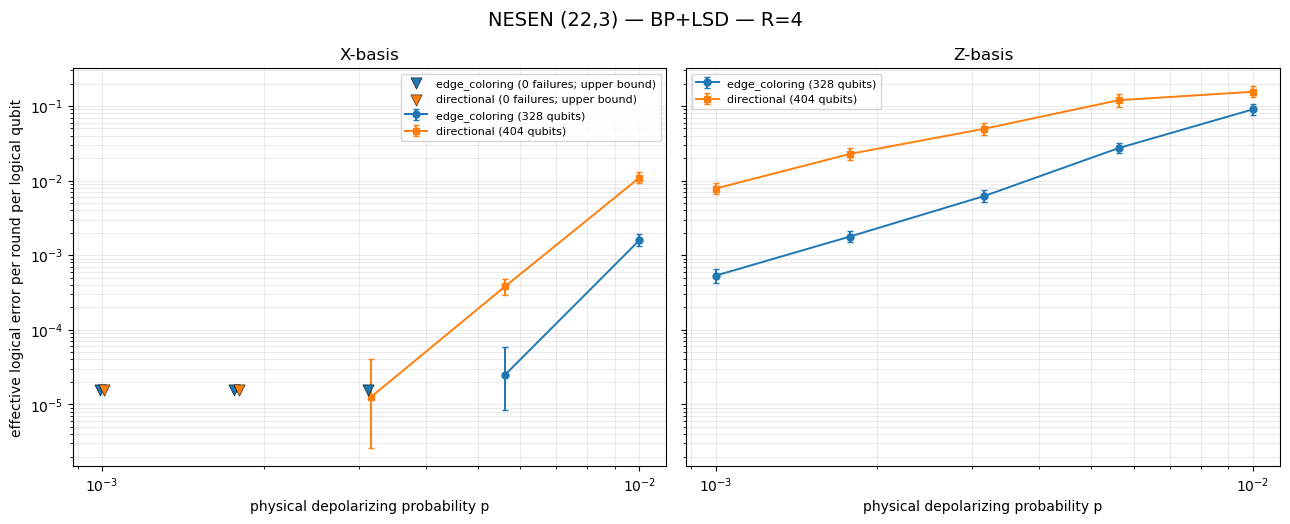

In [7]:
compare("NESEN", M=22, N=3, num_rounds=4)